## CNN Model for Binary Image Classification

### Expected Outcomes:
*   **Understand the architecture of Convolutional Neural Networks.**
*   **Implement CNNs using TensorFlow/Keras.**
*   **Apply image preprocessing and data augmentation techniques.**
*   **Train and evaluate a CNN for binary image classification.**
*   **Interpret prediction results and assess model performance.**

Let's start by importing the necessary libraries and setting up the environment. We'll use TensorFlow and Keras for building the CNN, and `os`, `numpy`, `matplotlib`, and `tensorflow_datasets` for data handling and visualization.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)  # Set TensorFlow seed for reproducibility
np.random.seed(42)      # Set NumPy seed for reproducibility

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.20.0


Next, we will download and prepare the 'cats_vs_dogs' dataset from TensorFlow Datasets. This dataset is perfect for binary image classification tasks. We'll split it into training and validation sets.

149574867/149574867 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
11480187/11480187 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Found 1027 files belonging to 2 classes.
Found 256 files belonging to 2 classes.
Classes: ['horses', 'humans']  (label 0 = horses, label 1 = humans)


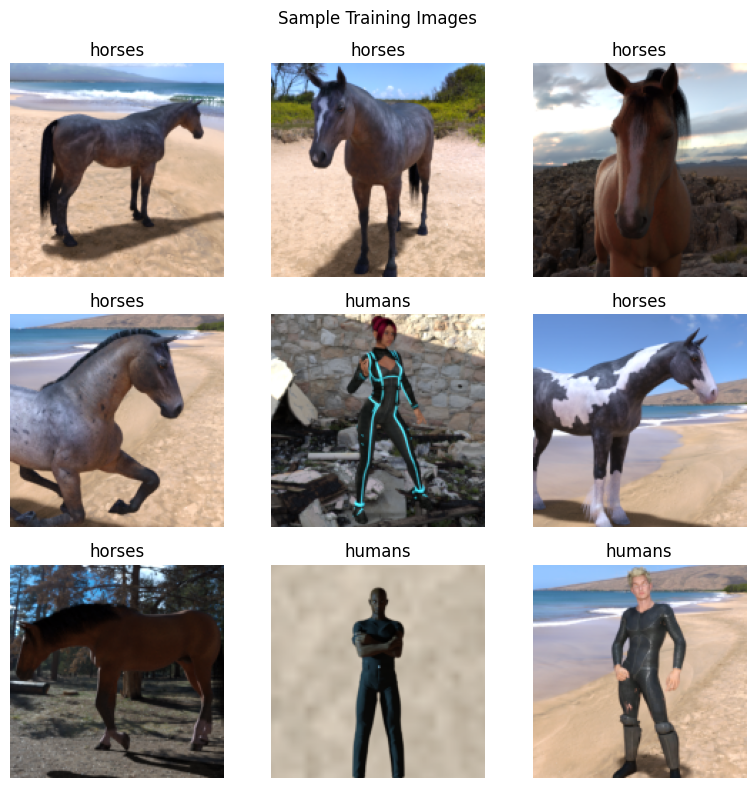

In [ ]:
IMG_SIZE = (150, 150) # Define the target size for all images
BATCH_SIZE = 32      # Define the batch size for training and validation

# Download and extract the 'horse-or-human' training dataset
train_zip = keras.utils.get_file(
    "horse-or-human.zip",
    origin="https://storage.googleapis.com/download.tensorflow.org/data/horse-or-human.zip",
    extract=True,
    cache_subdir="datasets/horse-or-human",
)
# Download and extract the 'validation-horse-or-human' validation dataset
val_zip = keras.utils.get_file(
    "validation-horse-or-human.zip",
    origin="https://storage.googleapis.com/download.tensorflow.org/data/validation-horse-or-human.zip",
    extract=True,
    cache_subdir="datasets/validation-horse-or-human",
)

# Construct the directory paths for the extracted datasets
train_dir = os.path.join(os.path.dirname(train_zip), "horse-or-human_extracted")
val_dir = os.path.join(os.path.dirname(val_zip), "validation-horse-or-human_extracted")

# Create TensorFlow datasets from the directories
train_ds = keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary", seed=42
)
val_ds = keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary", seed=42
)

# Get the class names (e.g., 'horses', 'humans')
class_names = train_ds.class_names
print(f"Classes: {class_names}  (label 0 = {class_names[0]}, label 1 = {class_names[1]})")

# Visualize Sample Images from the training dataset
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])]) # Display class name as title
        plt.axis("off")
plt.suptitle("Sample Training Images")
plt.tight_layout()
plt.show()

### 3. Preprocessing and Data Augmentation
Pixel values are rescaled from [0, 255] to [0, 1] inside the model (a `Rescaling` layer), and training images are randomly flipped, rotated, and zoomed on the fly so the model sees more variety and generalizes better.

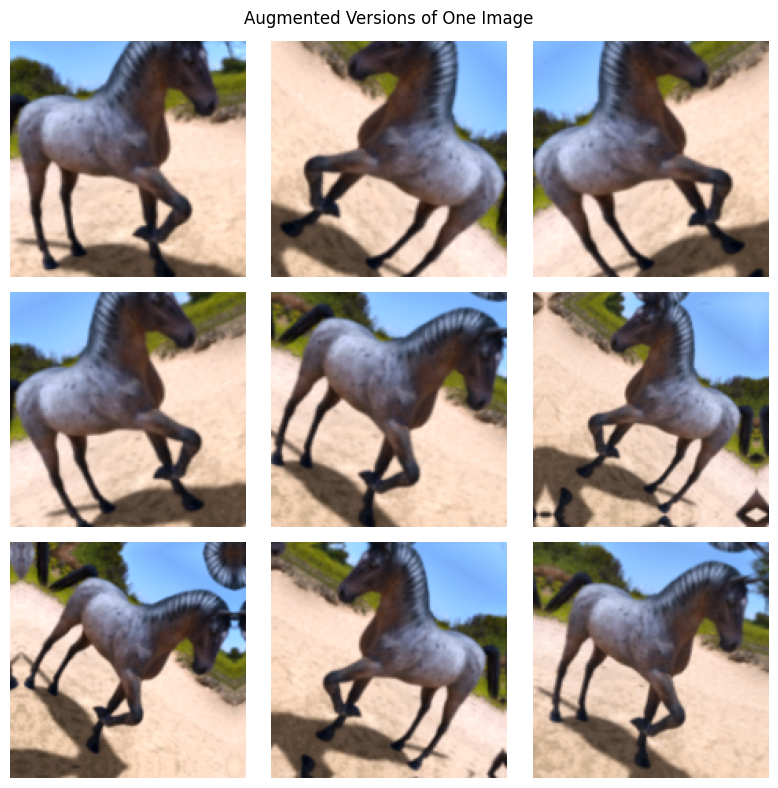

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),  # Randomly flip images horizontally
    layers.RandomRotation(0.15),     # Randomly rotate images by up to 15%
    layers.RandomZoom(0.15),        # Randomly zoom images by up to 15%
    layers.RandomContrast(0.1),     # Randomly adjust image contrast
], name="data_augmentation")

# Preview augmented versions of the same image to see the effect of augmentation
plt.figure(figsize=(8, 8))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented = data_augmentation(images[:1], training=True)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented[0].numpy().astype("uint8"))
        plt.axis("off")
plt.suptitle("Augmented Versions of One Image")
plt.tight_layout()
plt.show()

AUTOTUNE = tf.data.AUTOTUNE # Optimize data pipeline performance
# Apply data augmentation to the training dataset and prefetch for efficiency
train_ds_aug = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y)).prefetch(AUTOTUNE)
# Prefetch the validation dataset for efficiency
val_ds = val_ds.prefetch(AUTOTUNE)

Now, let's define the Convolutional Neural Network (CNN) model architecture using Keras. We'll use a sequential model with several `Conv2D` and `MaxPooling2D` layers, followed by `Flatten` and `Dense` layers. A `Dropout` layer will be added to help prevent overfitting.

In [ ]:
keras.utils.set_random_seed(42)  # Ensure reproducibility of weight initialization

model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)), # Input layer specifying image dimensions (height, width, channels)
    layers.Rescaling(1./255),                            # Rescale pixel values from [0, 255] to [0, 1]
    layers.Conv2D(16, 3, activation="relu"),             # First convolutional layer with 16 filters, 3x3 kernel, ReLU activation
    layers.MaxPooling2D(),                               # Max pooling layer to reduce spatial dimensions
    layers.Conv2D(32, 3, activation="relu"),             # Second convolutional layer with 32 filters
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),             # Third convolutional layer with 64 filters
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),             # Fourth convolutional layer with 64 filters
    layers.MaxPooling2D(),
    layers.Flatten(),                                    # Flatten the 3D output to 1D for dense layers
    layers.Dropout(0.5),                                 # Dropout layer to prevent overfitting (50% dropout rate)
    layers.Dense(64, activation="relu"),                 # Hidden dense layer with 64 units, ReLU activation
    layers.Dense(1, activation="sigmoid"),               # Output dense layer with 1 unit and sigmoid activation for binary classification
])

# Compile the model with Adam optimizer, binary crossentropy loss, and accuracy metric
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary() # Print a summary of the model architecture

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 15, 15, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 261,345 (1020.88 KB)

 Trainable params: 261,345 (1020.88 KB)

 Non-trainable params: 0 (0.00 B)

Now, we will train the CNN model using the prepared training and validation datasets. We'll train for a few epochs and observe the accuracy and loss during training.

In [ ]:
EPOCHS = 30 # Define the number of training epochs

# Define EarlyStopping callback to prevent overfitting
# It monitors validation accuracy and stops if it doesn't improve for 6 consecutive epochs,
# restoring the best weights found during training.
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=6, restore_best_weights=True
)

# Train the model using the augmented training data and validation data
history = model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=0, # Set to 1 for progress bar, 0 for silent training
    callbacks=[early_stop],
)

# Print training progress for each epoch
trained_epochs = len(history.history["loss"])
for epoch in range(trained_epochs):
    print(f"Epoch [{epoch+1:2d}/{trained_epochs}] | Train Loss: {history.history['loss'][epoch]:.4f} | "
          f"Train Acc: {history.history['accuracy'][epoch]*100:.1f}% | "
          f"Val Loss: {history.history['val_loss'][epoch]:.4f} | "
          f"Val Acc: {history.history['val_accuracy'][epoch]*100:.1f}%")

NameError: name 'train_ds_aug' is not defined

After training, it's important to visualize the training history to understand how the model performed. We'll plot the training and validation accuracy and loss over the epochs.

NameError: name 'history' is not defined

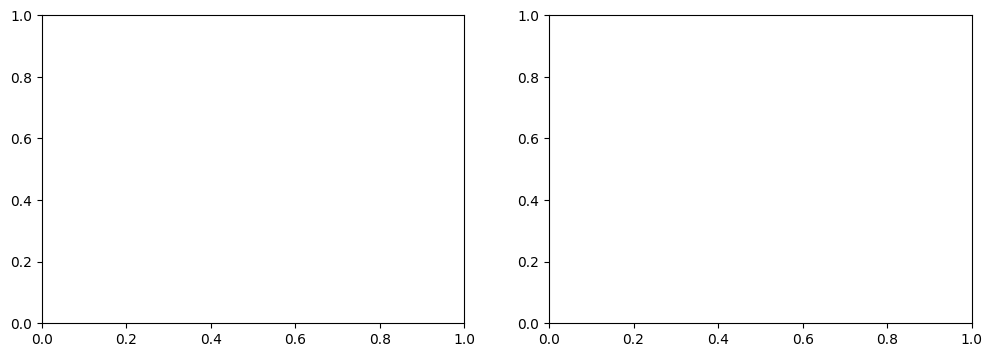

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4)) # Create a figure with two subplots for accuracy and loss

# Plot training and validation accuracy over epochs
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

# Plot training and validation loss over epochs
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

Finally, let's evaluate the model on the test dataset and interpret some predictions.


-- Final Results --
Validation Accuracy: 50.0%  (128/256 correct)

Confusion Matrix (rows = actual, cols = predicted)
                 pred:  horses  pred:  humans
actual:  horses               0             128
actual:  humans               0             128

Precision (humans): 50.0%  |  Recall (humans): 100.0%


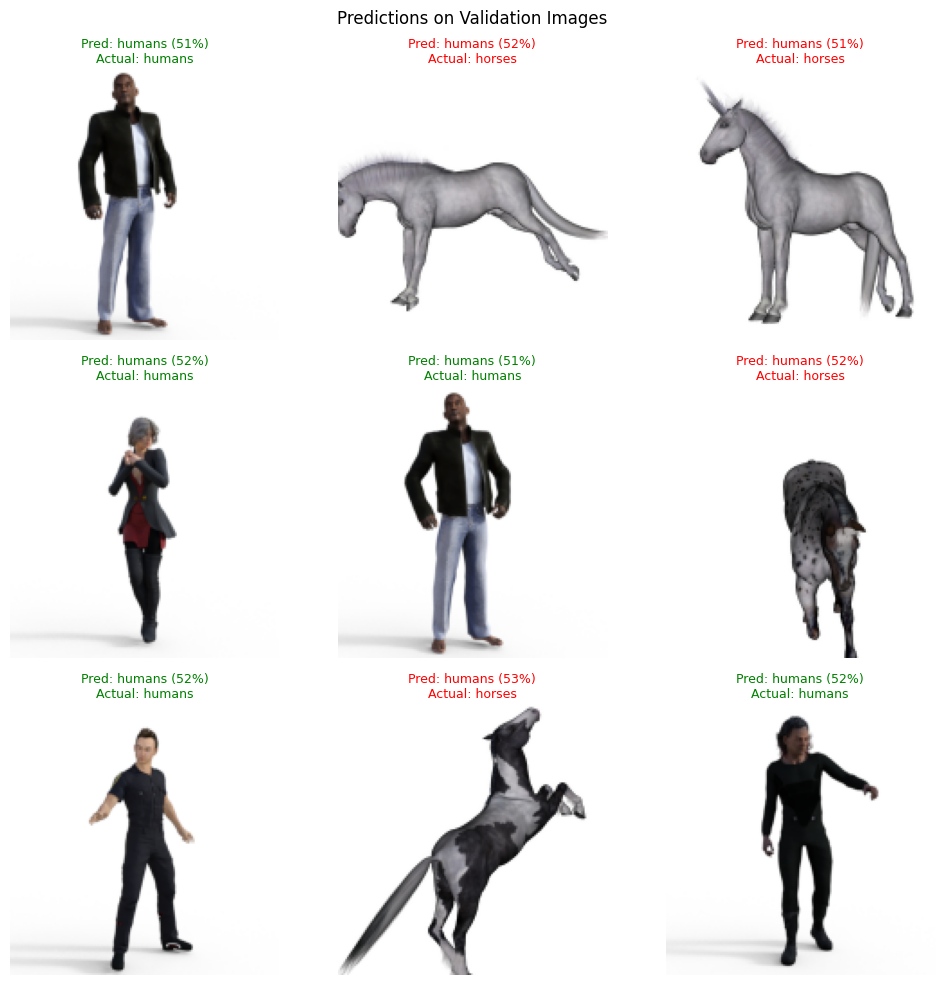

In [ ]:
print("\n-- Final Results --")
# Evaluate the model on the validation dataset to get final loss and accuracy
val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
n_val = sum(1 for _ in val_ds.unbatch()) # Calculate total number of validation samples
correct = int(round(val_accuracy * n_val))
print(f"Validation Accuracy: {val_accuracy*100:.1f}%  ({correct}/{n_val} correct)")

# Generate predictions for the confusion matrix
y_true = np.concatenate([y.numpy() for _, y in val_ds]).ravel() # True labels from validation set
y_prob = model.predict(val_ds, verbose=0).ravel()             # Predicted probabilities from the model
y_pred = (y_prob > 0.5).astype(int)                            # Convert probabilities to binary predictions (0 or 1)

# Manually create a confusion matrix
cm = np.zeros((2, 2), dtype=int)
for t, p in zip(y_true.astype(int), y_pred):
    cm[t, p] += 1

print("\nConfusion Matrix (rows = actual, cols = predicted)")
print(f"                 pred:{class_names[0]:>8s}  pred:{class_names[1]:>8s}")
for i, name in enumerate(class_names):
    print(f"actual:{name:>8s}  {cm[i,0]:>14d}  {cm[i,1]:>14d}")

# Calculate Precision and Recall for the positive class (class 1)
precision = cm[1,1] / (cm[0,1] + cm[1,1] + 1e-9) # Add epsilon to avoid division by zero
recall = cm[1,1] / (cm[1,0] + cm[1,1] + 1e-9)    # Add epsilon to avoid division by zero
print(f"\nPrecision ({class_names[1]}): {precision*100:.1f}%  |  Recall ({class_names[1]}): {recall*100:.1f}%")

# Visualize some predictions from the validation set
plt.figure(figsize=(10, 10))
for images, labels in val_ds.take(1):
    preds = model.predict(images, verbose=0).ravel()
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        actual = class_names[int(labels[i].numpy().item())]
        predicted = class_names[int(preds[i] > 0.5)]
        confidence = preds[i] if preds[i] > 0.5 else 1 - preds[i] # Calculate prediction confidence
        color = "green" if predicted == actual else "red" # Set color based on prediction correctness
        plt.title(f"Pred: {predicted} ({confidence*100:.0f}%)\nActual: {actual}", color=color, fontsize=9)
        plt.axis("off")
plt.suptitle("Predictions on Validation Images")
plt.tight_layout()
plt.show()